In [1]:
suppressPackageStartupMessages({
library(Seurat)
library(SeuratWrappers)
library(patchwork)
library(dplyr)
library(ggplot2)

})

theme_set(theme_classic(16))

# Set working directory for saving and accessing files
setwd("/data/pam/team333/skb/scratch/SNIP_paper/")
set.seed(123)

In [2]:
Hcon_obj <- readRDS(file = "04_analysis/seurat_obj/Hcon_harmony.rds")
Tmur_obj <- readRDS(file = "04_analysis/seurat_obj/Tmur_harmony.rds")

In [7]:
table(Hcon_obj@meta.data$sample)


 HconF_1  HconF_2 HconL3_1 HconL3_2  HconM_1  HconM_2 
     509     6005      610     2421      214      816 

In [6]:
# Add additional metadata field for life cycle stage to the seurat objects
stage_lookup <- c(
  HconF_1  = "Adult female", HconF_2  = "Adult female",
  HconM_1  = "Adult male",   HconM_2  = "Adult male",
  HconL3_1 = "L3 larvae",    HconL3_2 = "L3 larvae"
)

Hcon_obj$stage <- unname(stage_lookup[Hcon_obj$sample])

table(Hcon_obj$sample, Hcon_obj$stage)

          
           Adult female Adult male L3 larvae
  HconF_1           509          0         0
  HconF_2          6005          0         0
  HconL3_1            0          0       610
  HconL3_2            0          0      2421
  HconM_1             0        214         0
  HconM_2             0        816         0

In [9]:
# Add additional metadata field for life cycle stage to the seurat objects
stage_lookup <- c(
  TmurF_1  = "Adult female", TmurF_2  = "Adult female",
  TmurM_1  = "Adult male",   TmurM_2  = "Adult male"
)

Tmur_obj$stage <- unname(stage_lookup[Tmur_obj$sample])

table(Tmur_obj$sample, Tmur_obj$stage)

         
          Adult female Adult male
  TmurF_1         1282          0
  TmurF_2         1755          0
  TmurM_1            0        550
  TmurM_2            0        288

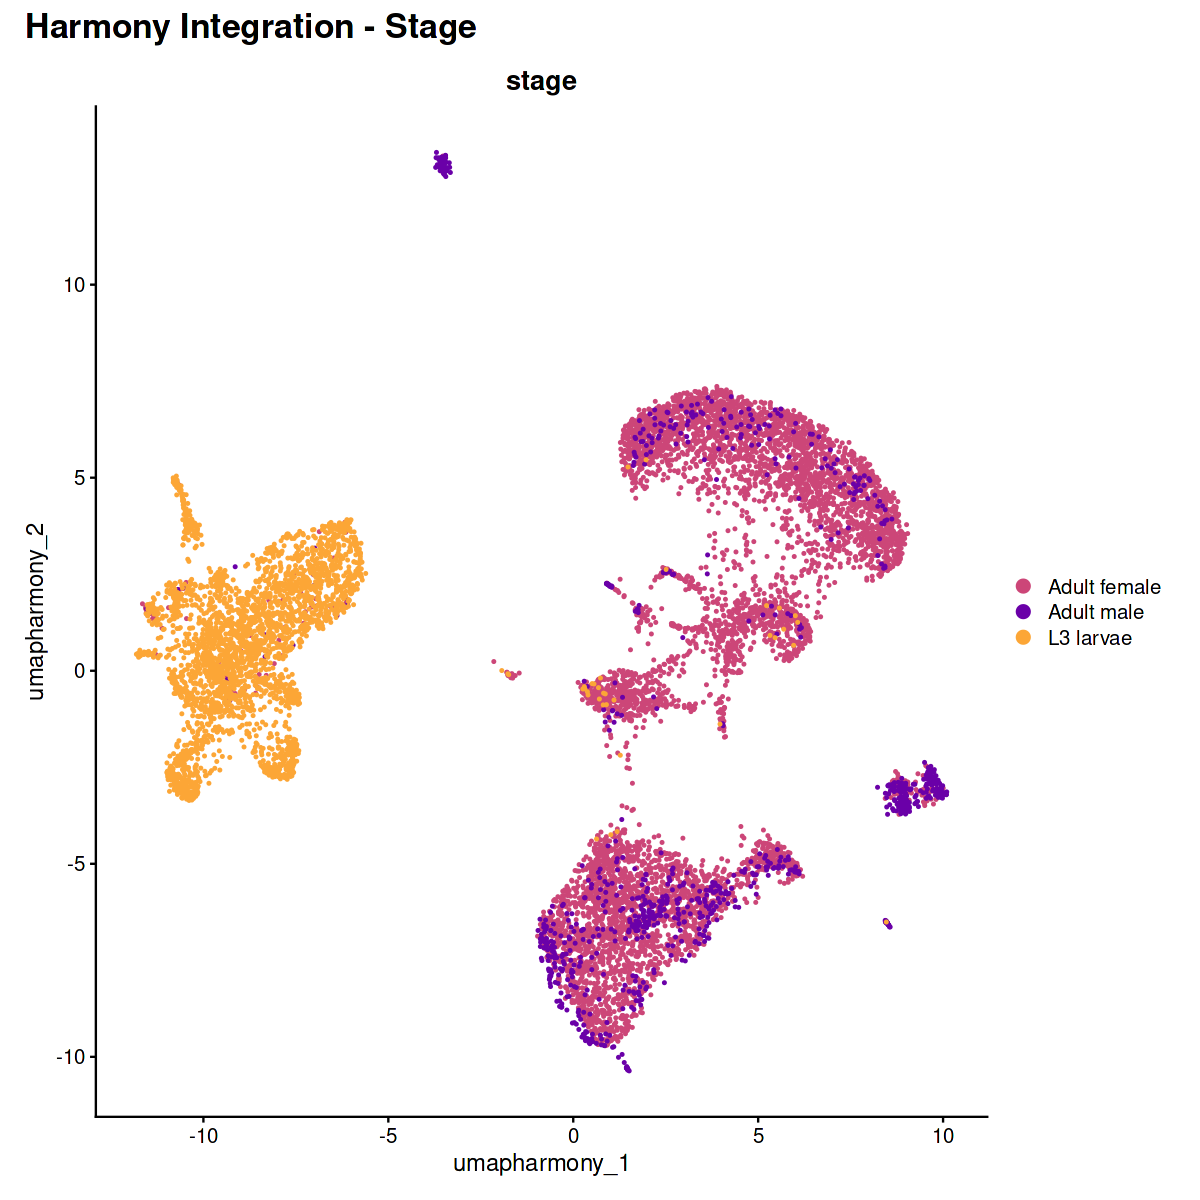

In [8]:
# Hcon stage clustering after harmony integration
options(repr.plot.width=10, repr.plot.height=10)
stage_cols <- c(
  "Adult female" = "#CC4678",
  "Adult male"   = "#6A00A8",
  "L3 larvae"    = "#FCA636"
)
DimPlot(Hcon_obj, reduction = "umap.harmony", 
        raster = FALSE, cols = stage_cols, group.by = c("stage")) +
            plot_annotation(title = 'Harmony Integration - Stage', 
                            theme = theme(plot.title = element_text(size = 20, face = "bold")))
ggsave(file = "./05_figures/hcon_harmony_stage.png", width = 20, height = 20, dpi = 600, units = "cm")

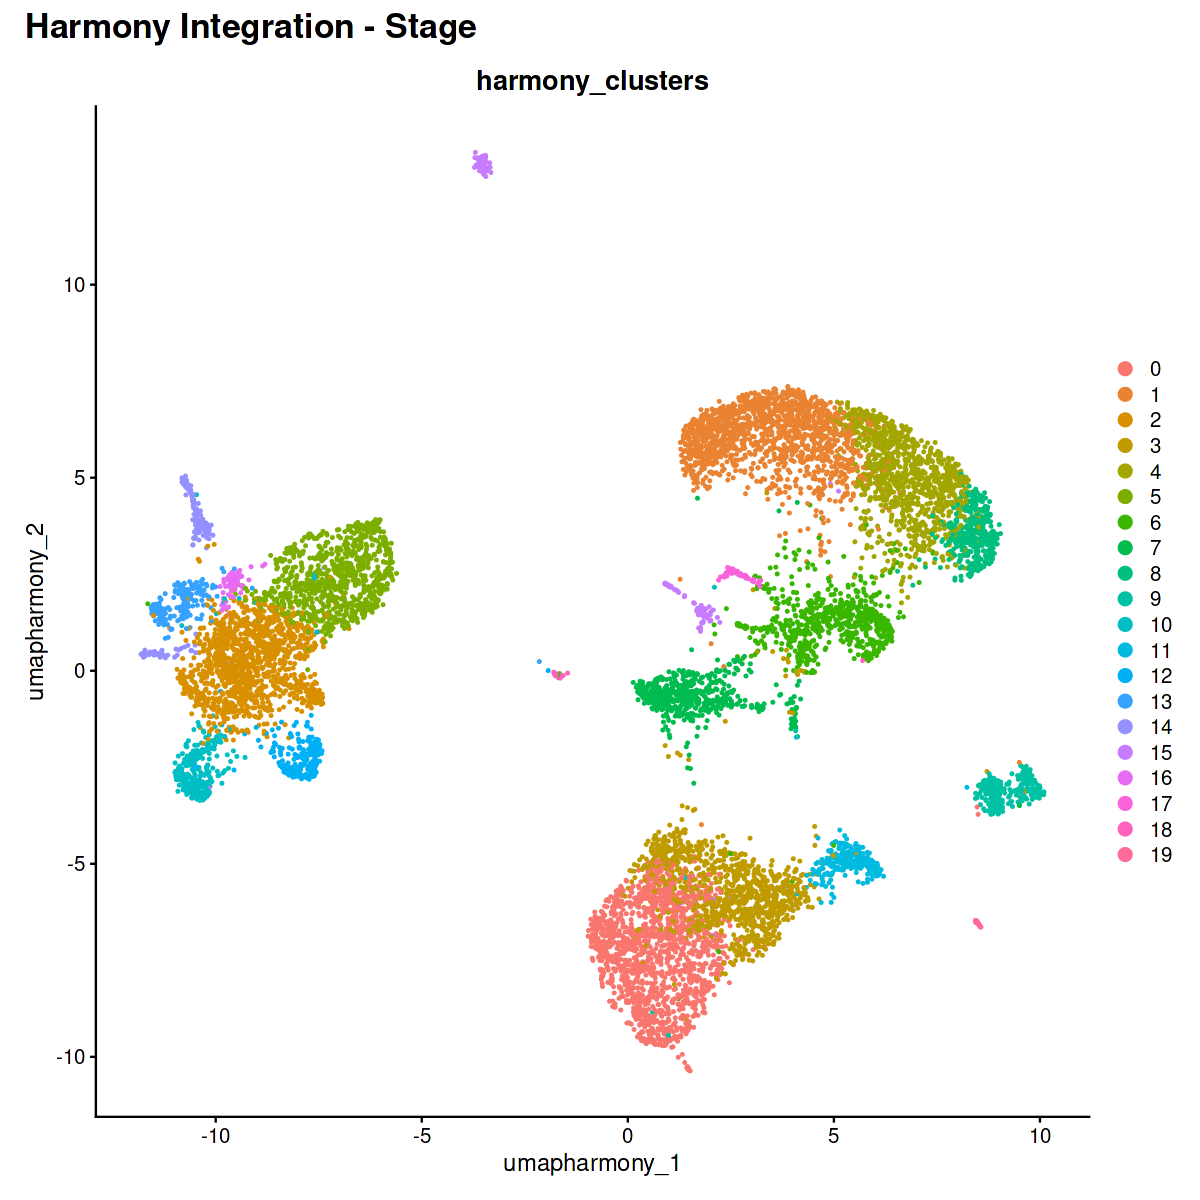

In [20]:
# Hcon cell clustering after harmony integration
DimPlot(Hcon_obj, reduction = "umap.harmony", raster = FALSE, 
        group.by = c("harmony_clusters")) + 
    plot_annotation(title = 'Harmony Integration - Stage', 
                    theme = theme(plot.title = element_text(size = 20, face = "bold")))
ggsave(file = "./05_figures/hcon_harmony_clusters.png", width = 20, height = 20, dpi = 600, units = "cm")

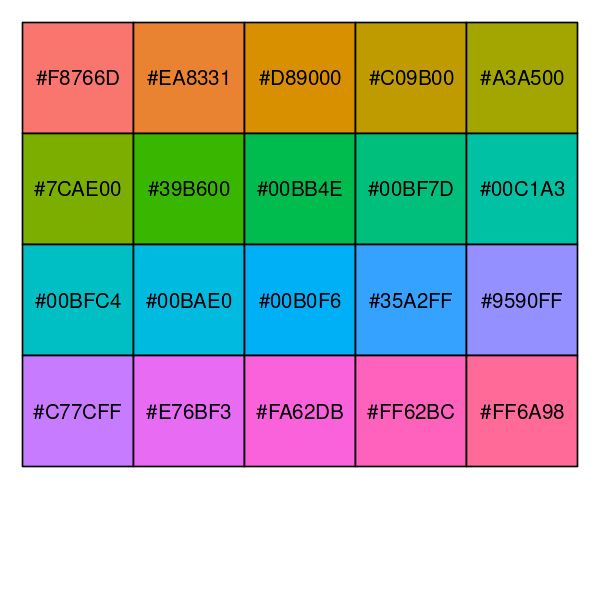

In [29]:
# Get hex colour code used in Hcon cell clusters dimplot to use in gene marker plots
library(scales)
options(repr.plot.width=5, repr.plot.height=5)
show_col(hue_pal()(20))
    # Cluster 16 = #E76BF3
    # Cluster 6 = #39B600
    # Cluster 9 = #00C1A3

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


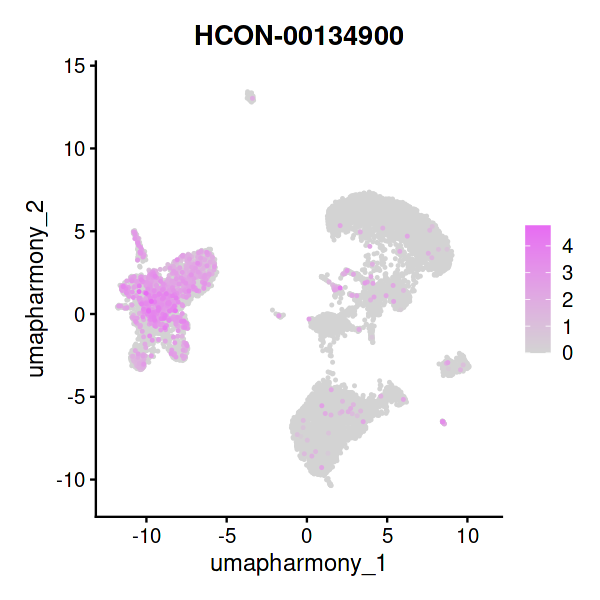

In [39]:
# Plot expression of Cluster 16 marker gene HCON_00134900
options(repr.plot.width=5, repr.plot.height=5)
FeaturePlot(Hcon_obj, reduction = "umap.harmony", raster = FALSE,
            features = "HCON-00134900", order = TRUE) +
  scale_colour_gradientn(colours = c("lightgrey", "#E76BF3"))
ggsave(file = "05_figures/HCON-00134900.png", width = 20, height = 20, dpi = 600, units = "cm")

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


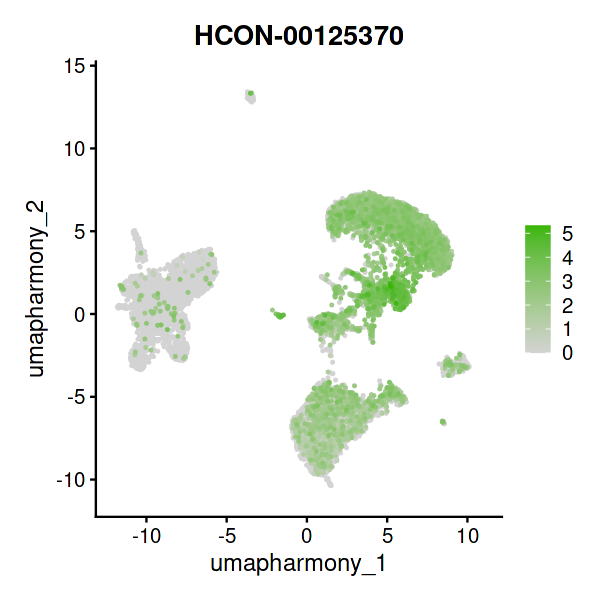

In [42]:
# Plot expression of Cluster 6 marker gene HCON_00125370
FeaturePlot(Hcon_obj, reduction = "umap.harmony", raster = FALSE,
            features = "HCON-00125370", order = TRUE) +
  scale_colour_gradientn(colours = c("lightgrey", "#39B600"))
ggsave(file = "05_figures/HCON-00125370.png", width = 20, height = 20, dpi = 600, units = "cm")

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


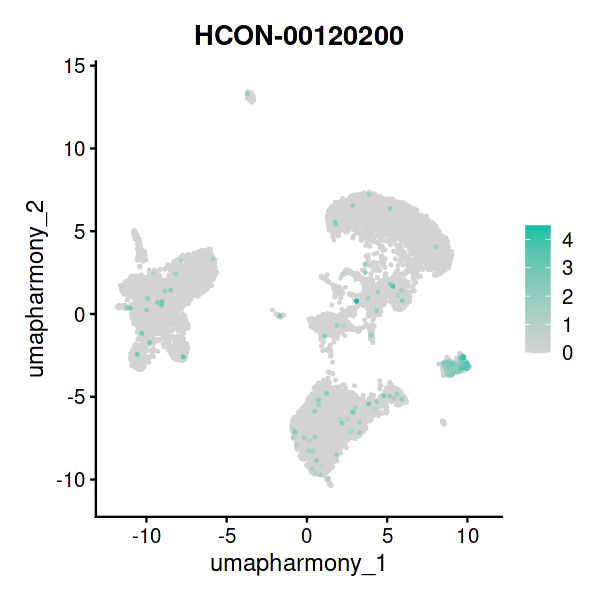

In [43]:
# Plot expression of Cluster 9 marker gene HCON_00120200
FeaturePlot(Hcon_obj, reduction = "umap.harmony", raster = FALSE,
            features = "HCON-00120200", order = TRUE) +
  scale_colour_gradientn(colours = c("lightgrey", "#00C1A3"))
ggsave(file = "05_figures/HCON-00120200.png", width = 20, height = 20, dpi = 600, units = "cm")

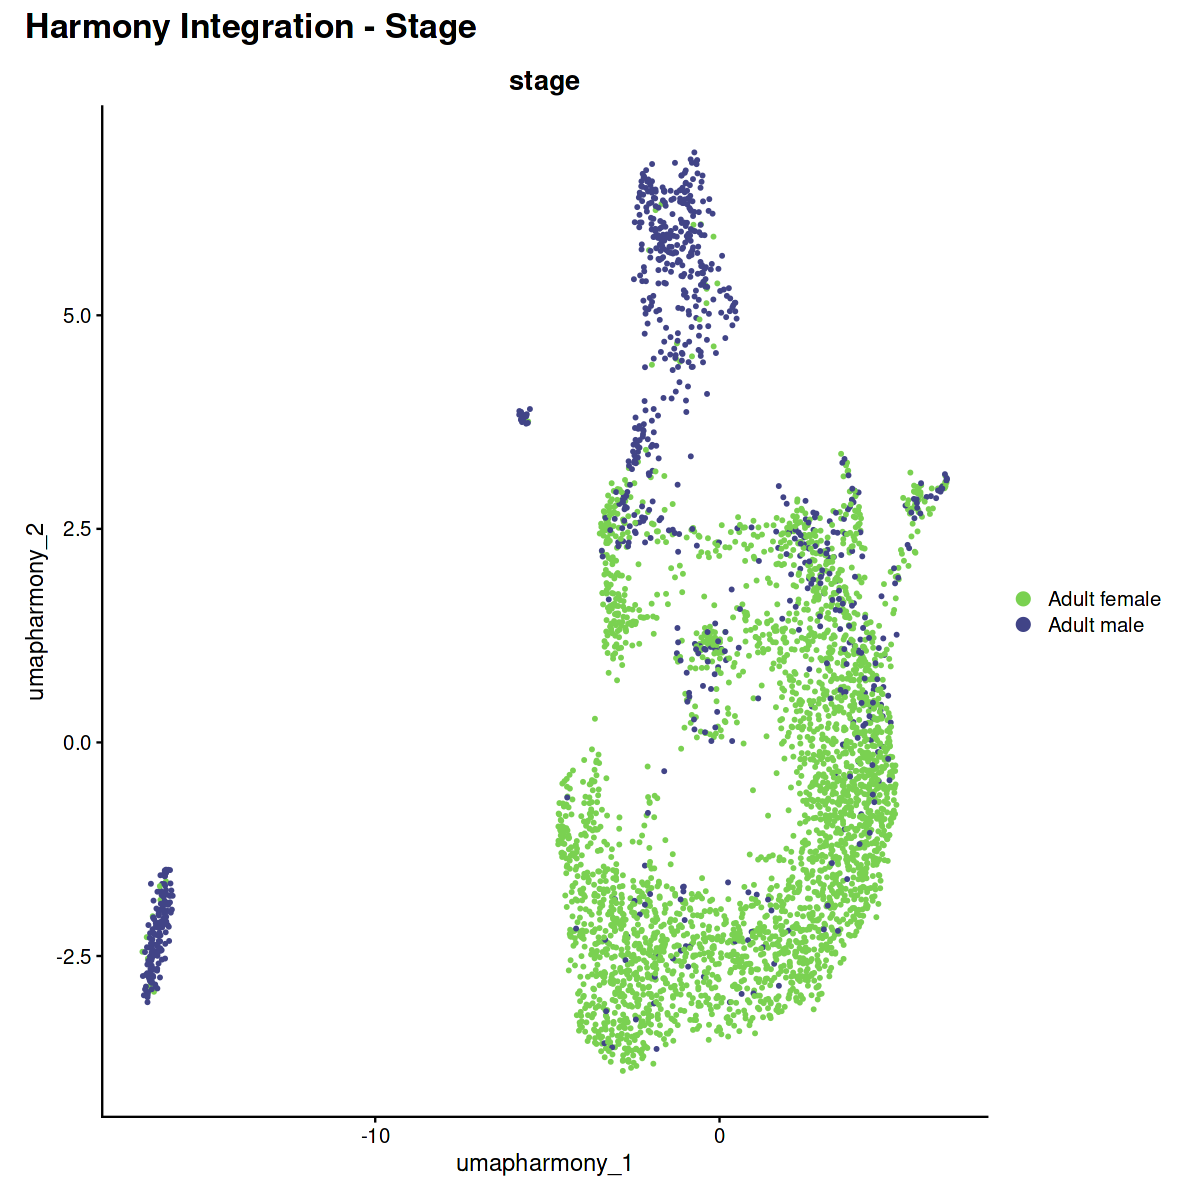

In [33]:
# Tmuris stage clustering after harmony integration
options(repr.plot.width=10, repr.plot.height=10)
stage_cols <- c(
  "Adult female" = "#7AD151",
  "Adult male"   = "#414487"
)
DimPlot(Tmur_obj, reduction = "umap.harmony", raster = FALSE, 
        cols = stage_cols, group.by = c("stage")) + 
    plot_annotation(title = 'Harmony Integration - Stage', 
                    theme = theme(plot.title = element_text(size = 20, face = "bold")))
ggsave(file = "05_figures/tmur_harmony_stage.png", width = 20, height = 20, dpi = 600, units = "cm")

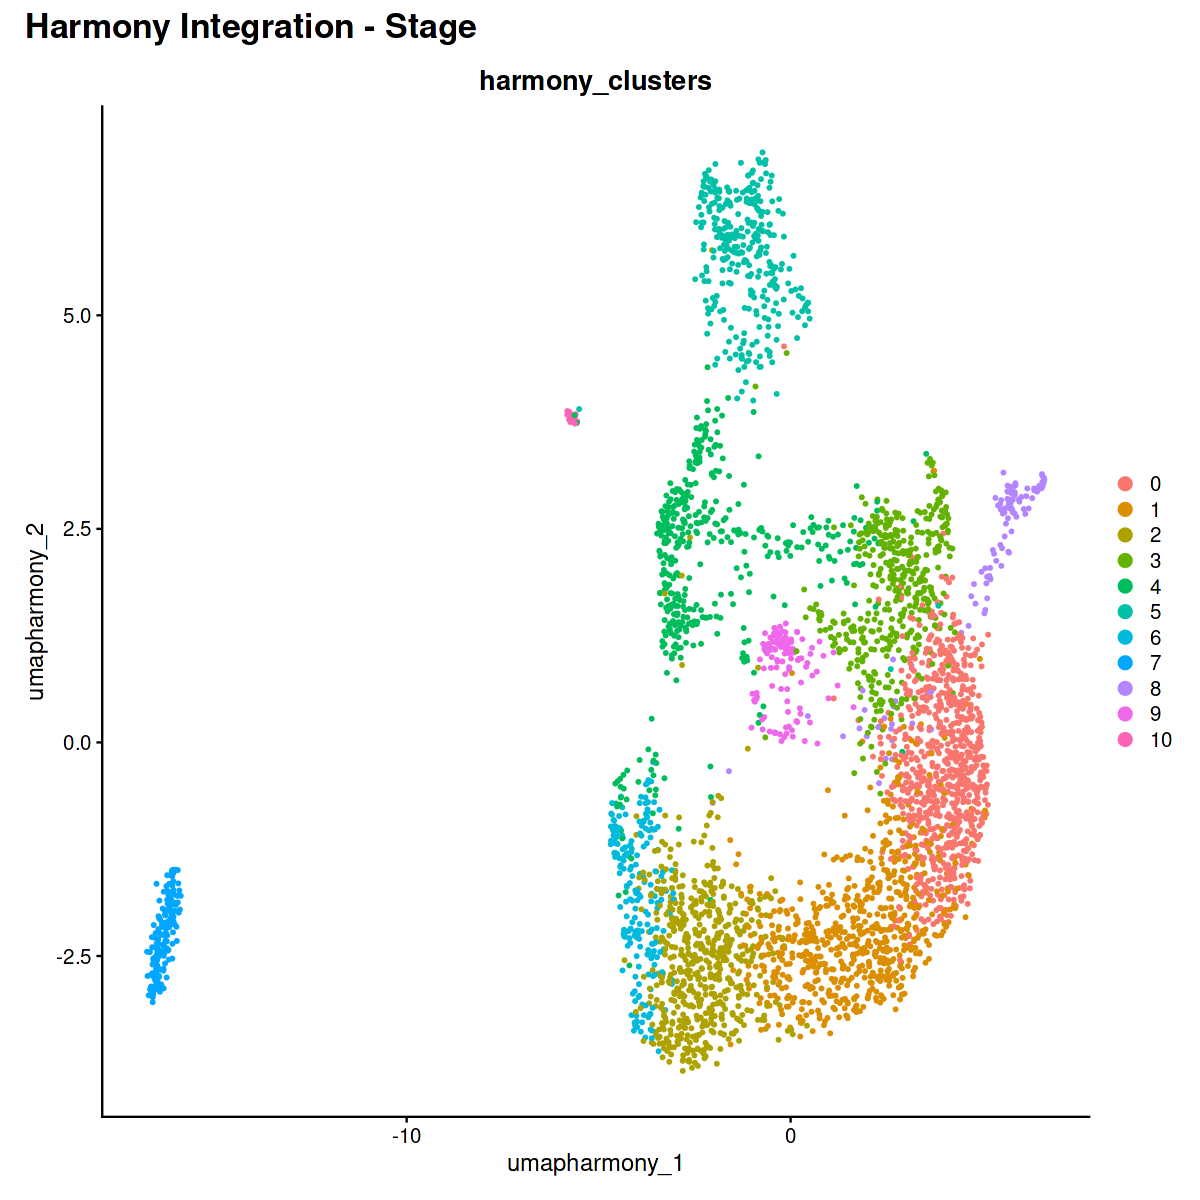

In [25]:
# Tmuris cell clustering after harmony integration
DimPlot(Tmur_obj, reduction = "umap.harmony", raster = FALSE, 
        group.by = c("harmony_clusters")) + 
    plot_annotation(title = 'Harmony Integration - Stage', 
                    theme = theme(plot.title = element_text(size = 20, face = "bold")))
ggsave(file = "./05_figures/tmur_harmony_clusters.png", width = 20, height = 20, dpi = 600, units = "cm")

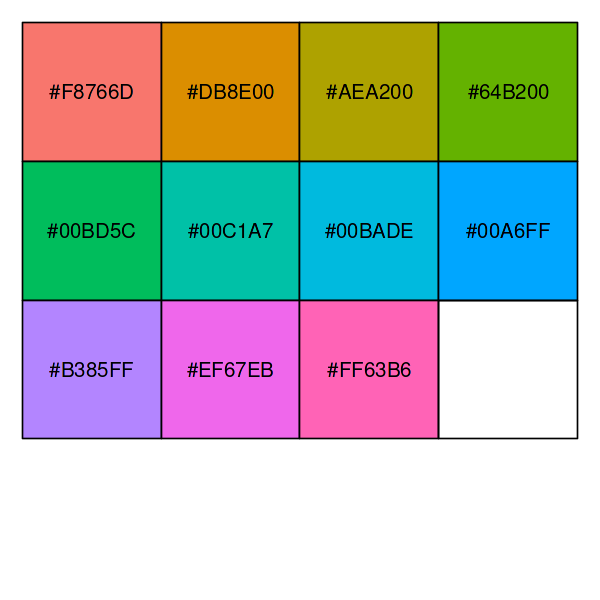

In [31]:
# Get hex colour code used in Tmur cell clusters dimplot to use in gene marker plots
library(scales)
options(repr.plot.width=5, repr.plot.height=5)
show_col(hue_pal()(11))
    # Cluster 5 = #00C1A7
    # Cluster 6 = #00BADE
    # Cluster 8 = #B385FF

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


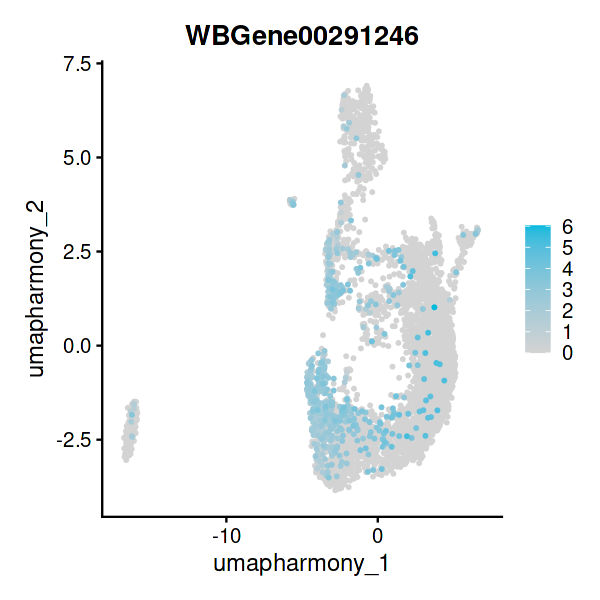

In [49]:
# Plot expression of Cluster 6 marker gene WBGene00291246
options(repr.plot.width=5, repr.plot.height=5)
FeaturePlot(Tmur_obj, reduction = "umap.harmony", raster = FALSE,
            features = "WBGene00291246", order = TRUE) +
  scale_colour_gradientn(colours = c("lightgrey", "#00BADE"))
ggsave(file = "05_figures/WBGene00291246.png", width = 20, height = 20, dpi = 600, units = "cm")

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


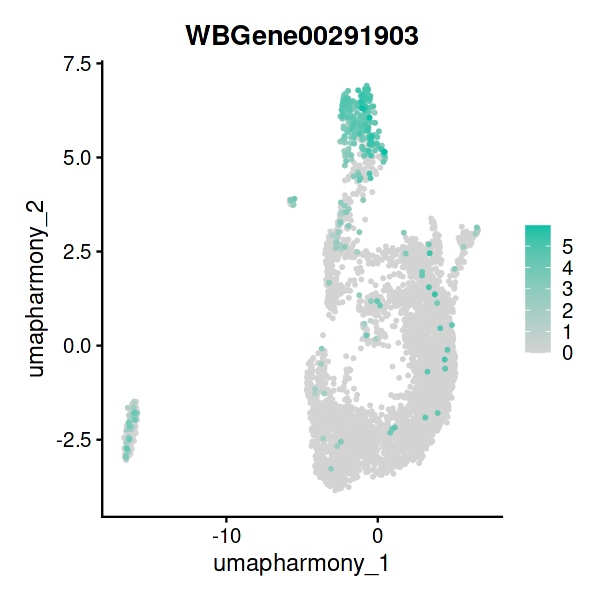

In [48]:
# Plot expression of Cluster 5 marker gene WBGene00291903
FeaturePlot(Tmur_obj, reduction = "umap.harmony", raster = FALSE,
            features = "WBGene00291903", order = TRUE) +
  scale_colour_gradientn(colours = c("lightgrey", "#00C1A7"))
ggsave(file = "05_figures/WBGene00291903.png", width = 20, height = 20, dpi = 600, units = "cm")

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


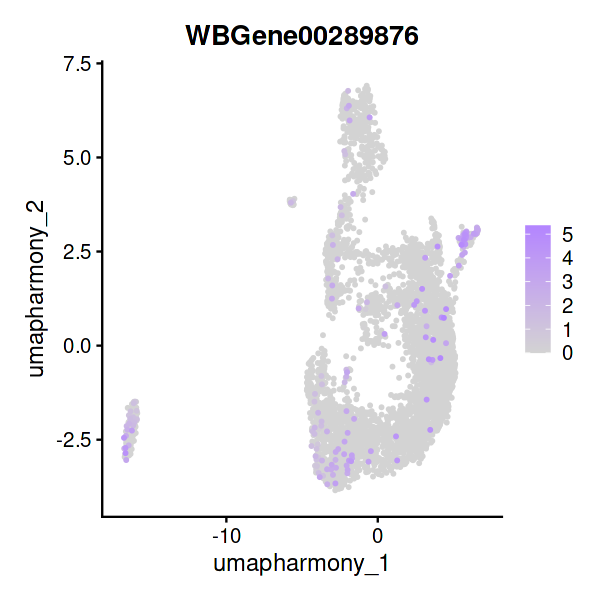

In [47]:
# Plot expression of Cluster 8 marker gene WBGene00289876
FeaturePlot(Tmur_obj, reduction = "umap.harmony", raster = FALSE,
            features = "WBGene00289876", order = TRUE) +
  scale_colour_gradientn(colours = c("lightgrey", "#B385FF"))
ggsave(file = "05_figures/WBGene00289876.png", width = 20, height = 20, dpi = 600, units = "cm")